# Part 3 Extra: Secret messages 🔐

**Uses:** Lectures 5-8 - strings and slicing, loops, `%` (remainder), **functions** (L07) and **dictionaries** (L08).

**What you will build:**
1. The **Caesar cipher**: shift every letter, so `"pip"` becomes `"sls"`
2. A code breaker that tries **all 26 keys** (brute force)
3. A *smarter* code breaker that counts letters with a dictionary
4. A final secret message for **you** to crack

> 🐍 **Pip says:** "Julius Caesar hid his letters this way 2,000 years ago. Let's break his code in 10 lines."

## 1. Letters are positions

The Caesar cipher moves every letter a fixed number of places in the alphabet. With a shift of 3: a → d, b → e, ..., and at the end it **wraps around**: x → a, y → b, z → c.

First we need each letter's **position** (a = 0, b = 1, ..., z = 25). A dictionary is perfect for that.

In [1]:
LOWER = "abcdefghijklmnopqrstuvwxyz"
UPPER = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"

POSITION = {}
for i in range(26):
    POSITION[LOWER[i]] = i      # "a" -> 0, "b" -> 1, ...
    POSITION[UPPER[i]] = i      # "A" -> 0, "B" -> 1, ...

print(POSITION["a"], POSITION["e"], POSITION["Z"])

0 4 25


## 2. Shift one letter, then a whole message

`% 26` is the remainder from Lecture 2. It makes the alphabet a **circle**: position 25 + 3 = 28, and 28 % 26 = 2, which is "c".

Only letters move. Spaces, digits and punctuation stay as they are.

In [2]:
def shift_letter(letter, shift):
    if letter in LOWER:
        return LOWER[(POSITION[letter] + shift) % 26]
    if letter in UPPER:
        return UPPER[(POSITION[letter] + shift) % 26]
    return letter                  # not a letter: keep it

print(shift_letter("a", 3), shift_letter("z", 3), shift_letter("P", 3), shift_letter("!", 3))

d c S !


In [3]:
def encrypt(text, shift):
    result = ""
    for letter in text:
        result = result + shift_letter(letter, shift)
    return result

def decrypt(text, shift):
    return encrypt(text, -shift)   # going back = shifting the other way

secret = encrypt("Meet me at the falafel stand at 8!", 3)
print(secret)
print(decrypt(secret, 3))

Phhw ph dw wkh idodiho vwdqg dw 8!
Meet me at the falafel stand at 8!


**Test it** (Lecture 8 habit): for every shift, `decrypt(encrypt(x))` must give back `x`. Python's `%` even handles negative numbers nicely: `-3 % 26` is `23`.

In [4]:
message = "Pip loves Python, 100%!"
all_good = True
for shift in range(26):
    if decrypt(encrypt(message, shift), shift) != message:
        all_good = False
        print("Problem with shift", shift)
print("All 26 shifts work:", all_good)
print(-3 % 26)

All 26 shifts work: True
23


### Real life: ROT13

A shift of **13** is called **ROT13**. Online forums used it to hide spoilers and puzzle answers. Since 13 + 13 = 26, encrypting **twice** gives back the original!

In [5]:
spoiler = "The butler did it."
hidden = encrypt(spoiler, 13)
print(hidden)
print(encrypt(hidden, 13))

Gur ohgyre qvq vg.
The butler did it.


> **Try this**
> - Encrypt your name with shift 5. Send it to a friend with the shift, and let them decode it.
> - What does `encrypt("abc xyz", 1)` print? Predict, then run.

## 3. Break it: brute force

Pip intercepted this message. We **don't know** the shift. But there are only 26 possible shifts... so let's simply try them **all** and look for the one that reads like English.

In [6]:
intercepted = 'Lclyf lclupun aol zlh iyllgl ylhjolz aol zayllaz vm Als Hcpc. Wlvwsl slhcl aolpy klzrz, tlla myplukz ulhy aol ilhjo, huk hynbl hivba aol ilza wshjl mvy obttbz. Wpw aol zuhrl wylmlyz aol ilujo ulea av aol pjl jylht zlssly, dolyl ol ylhkz zljyla tlzzhnlz huk rllwz lclyf vul vm aolt.'

print(intercepted)

Lclyf lclupun aol zlh iyllgl ylhjolz aol zayllaz vm Als Hcpc. Wlvwsl slhcl aolpy klzrz, tlla myplukz ulhy aol ilhjo, huk hynbl hivba aol ilza wshjl mvy obttbz. Wpw aol zuhrl wylmlyz aol ilujo ulea av aol pjl jylht zlssly, dolyl ol ylhkz zljyla tlzzhnlz huk rllwz lclyf vul vm aolt.


In [7]:
for shift in range(26):
    print(shift, decrypt(intercepted, shift)[:40])   # first 40 characters are enough

0 Lclyf lclupun aol zlh iyllgl ylhjolz aol
1 Kbkxe kbktotm znk ykg hxkkfk xkginky znk
2 Jajwd jajsnsl ymj xjf gwjjej wjfhmjx ymj
3 Izivc izirmrk xli wie fviidi viegliw xli
4 Hyhub hyhqlqj wkh vhd euhhch uhdfkhv wkh
5 Gxgta gxgpkpi vjg ugc dtggbg tgcejgu vjg
6 Fwfsz fwfojoh uif tfb csffaf sfbdift uif
7 Every evening the sea breeze reaches the
8 Dudqx dudmhmf sgd rdz aqddyd qdzbgdr sgd
9 Ctcpw ctclgle rfc qcy zpccxc pcyafcq rfc
10 Bsbov bsbkfkd qeb pbx yobbwb obxzebp qeb
11 Aranu arajejc pda oaw xnaava nawydao pda
12 Zqzmt zqzidib ocz nzv wmzzuz mzvxczn ocz
13 Ypyls ypyhcha nby myu vlyyty lyuwbym nby
14 Xoxkr xoxgbgz max lxt ukxxsx kxtvaxl max
15 Wnwjq wnwfafy lzw kws tjwwrw jwsuzwk lzw
16 Vmvip vmvezex kyv jvr sivvqv ivrtyvj kyv
17 Uluho uludydw jxu iuq rhuupu huqsxui jxu
18 Tktgn tktcxcv iwt htp qgttot gtprwth iwt
19 Sjsfm sjsbwbu hvs gso pfssns fsoqvsg hvs
20 Rirel riravat gur frn oerrmr ernpurf gur
21 Qhqdk qhqzuzs ftq eqm ndqqlq dqmotqe ftq
22 Pgpcj pgpytyr esp dpl mcppkp cplnspd es

👀 One line jumps out as English. That's **brute force**: try every key. It works because the Caesar cipher has only 26 keys - a computer tries them all in a blink.

But *you* had to read 26 lines to spot the right one. Can the computer find it **by itself**?

## 4. Break it smarter: count the letters

In English, the most common letter is usually **e**. So: count the letters of the secret message with a dictionary. The most common one is probably an encrypted "e"!

In [8]:
def letter_counts(text):
    counts = {}
    for letter in LOWER:
        counts[letter] = 0                       # every letter starts at 0
    for letter in text:
        if letter in POSITION:                   # skip spaces and punctuation
            small = LOWER[POSITION[letter]]      # "A" and "a" count together
            counts[small] = counts[small] + 1
    return counts

def most_common(counts):
    best = "a"
    for letter in counts:
        if counts[letter] > counts[best]:        # the "max so far" pattern from L06
            best = letter
    return best

secret_counts = letter_counts(intercepted)
print(secret_counts)
print("Most common:", most_common(secret_counts))

{'a': 18, 'b': 4, 'c': 6, 'd': 1, 'e': 1, 'f': 2, 'g': 1, 'h': 15, 'i': 5, 'j': 7, 'k': 5, 'l': 57, 'm': 5, 'n': 3, 'o': 15, 'p': 6, 'q': 0, 'r': 3, 's': 6, 't': 6, 'u': 10, 'v': 7, 'w': 7, 'x': 0, 'y': 17, 'z': 18}
Most common: l


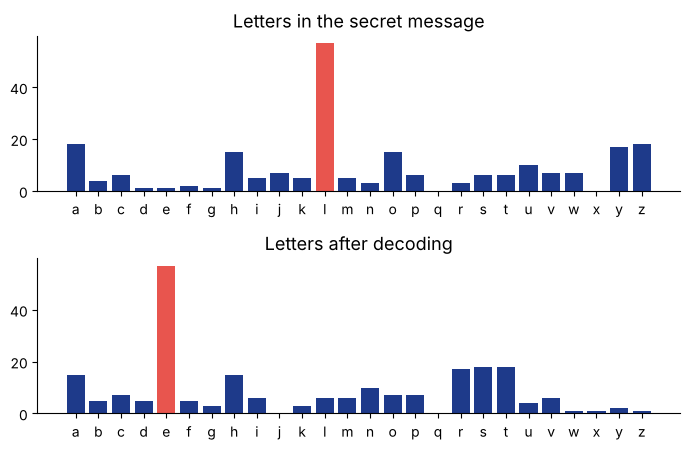

In [9]:
import matplotlib.pyplot as plt     # drawing toolbox (Lecture 10 - just run it)

def plot_counts(ax, counts, title):
    top = most_common(counts)
    colors = []
    for letter in LOWER:
        if letter == top:
            colors.append("#E8554E")          # highlight the most common letter
        else:
            colors.append("#1E3A8A")
    ax.bar(list(LOWER), list(counts.values()), color=colors)
    ax.set_title(title, fontsize=13)
    ax.spines[["top", "right"]].set_visible(False)

decoded = decrypt(intercepted, (POSITION[most_common(secret_counts)] - POSITION["e"]) % 26)
fig, axes = plt.subplots(2, 1, figsize=(7, 4.6))
plot_counts(axes[0], secret_counts, "Letters in the secret message")
plot_counts(axes[1], letter_counts(decoded), "Letters after decoding")
plt.tight_layout()
plt.show()

The whole bar pattern just **slides** along the alphabet. The tallest red bar slides back to **e**. So the shift is the distance from "e" to the most common letter:

In [10]:
def crack(text):
    top = most_common(letter_counts(text))
    shift = (POSITION[top] - POSITION["e"]) % 26     # distance from "e"
    print("Most common letter:", top, "-> guessed shift:", shift)
    return decrypt(text, shift)

print(crack(intercepted))

Most common letter: l -> guessed shift: 7
Every evening the sea breeze reaches the streets of Tel Aviv. People leave their desks, meet friends near the beach, and argue about the best place for hummus. Pip the snake prefers the bench next to the ice cream seller, where he reads secret messages and keeps every one of them.


🎉 Cracked without reading 26 lines!

### When the smart trick fails

Counting letters needs **enough text**. A short message may not have many e's at all:

In [11]:
short_secret = 'Kl Sls! Rxu ode lv dw urrp 101, eulqj d pds.'
print(crack(short_secret))

Most common letter: d -> guessed shift: 25
Lm Tmt! Syv pef mw ex vssq 101, fvmrk e qet.


Gibberish! Not a single "e" in the original message, so the guess is wrong. **Brute force still works** (try it!). Lesson for debugging: a method that works on one example can fail on another - always test several cases.

## 5. Real life: why your WhatsApp is safe

The Caesar cipher has 26 keys, so it breaks in a blink. Modern encryption (the kind behind `https://` websites and WhatsApp) uses keys with **128 bits** or more. How long would it take to try them all, even at a **trillion** tries per second?

In [12]:
num_keys = 2 ** 128                          # number of possible 128-bit keys
speed = 10 ** 12                             # a trillion tries every second
seconds_per_year = 60 * 60 * 24 * 365
years = num_keys / speed / seconds_per_year
print(num_keys)
print(f"{years:.1e} years")                  # .1e = scientific notation

340282366920938463463374607431768211456
1.1e+19 years


That is about 10,000,000,000,000,000,000 years - far longer than the age of the universe (about 14 billion years). Brute force is hopeless. Same idea as Caesar, **way** more keys.

## 6. Your mission 🕵️

Pip left you a message. Decode it with `crack(...)` or with the brute-force loop. Uncomment one line and run it!

In [13]:
final_message = 'Hpww ozyp, nzop mcplvpc! Jzf fdpo qfynetzyd, wzzad lyo otnetzylctpd ez nclnv l dpncpe xpddlrp. Ata esp dylvp td gpcj aczfo zq jzf. Dpp jzf ty Alce 4!'
print(final_message)

# print(crack(final_message))

Hpww ozyp, nzop mcplvpc! Jzf fdpo qfynetzyd, wzzad lyo otnetzylctpd ez nclnv l dpncpe xpddlrp. Ata esp dylvp td gpcj aczfo zq jzf. Dpp jzf ty Alce 4!


## 🏆 Challenges

**Easy**
- Encrypt a message for a friend with your own secret shift. Can they crack it with `crack`?
- Write `rot13(text)` in one line using `encrypt`.

**Medium**
- Change `crack` to print the **3 best guesses** (using the 3 most common letters). Hint: copy the counts dictionary, find the top letter, set it to 0, repeat.
- Brute force with a score: give each of the 26 decodings a score = how many times `" the "` appears, and print only the best one.

**Spicy 🌶️**
- **Vigenère cipher:** use a keyword like `"pip"`: shift the 1st letter by p (15), the 2nd by i (8), the 3rd by p (15), and repeat. Why does letter counting no longer work?